# 08 · Fairness by age

**Questions this notebook answers**

1. At the project threshold, are customers of different ages stepped up at different rates? Is fraud
   caught at different rates? Are good customers bothered (false positives) at different rates?
2. Which of those gaps are clear enough to call real, and which cannot be told apart from noise?
3. Does the model need `customer_age` at all?

**Method, fixed before any result** (`notes/00_preregistration.md`, amendment A5):

- Age bands 18–29, 30–44, 45–59, 60+ (chosen from a label-free look at the age distribution).
- Dev out-of-fold scores of the final pipeline from CV repeat r0, so every dev row is scored once by a
  model that did not train on it. **The holdout is not used.** One threshold for everyone: the project's.
- Per band: step-up rate, recall, precision, false-positive rate (FPR), each with a stratified bootstrap
  95% interval, plus the number of fraud cases. With so few fraud cases per band, intervals are wide.
- Each band is compared with all other dev rows. 4 bands × 4 metrics = 16 comparisons, so a gap counts as
  **real only if its Bonferroni-adjusted interval excludes 0**. Otherwise it is "not distinguishable". That
  is **not** evidence of fairness.
- The model without `customer_age` is compared on the same 15 folds (paired, corrected t-test on PR-AUC).

No causal or legal claim is made. Age is the only person attribute in the data, and the data's
provenance is unspecified.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from fraud_e2e import config as C
from fraud_e2e import plots as P
from fraud_e2e.cv import corrected_ttest, load_result, metric_ci, run_cv, save_result
from fraud_e2e.data import load_raw
from fraud_e2e.fairness import (
    AGE_LABELS,
    ALPHA_ADJ,
    METRICS,
    N_BOOT,
    N_COMPARISONS,
    age_group,
    group_gaps,
    group_metrics,
    overall_rates,
)
from fraud_e2e.reporting import read_json, write_csv, write_json
from fraud_e2e.splits import dev_only
from fraud_e2e.stats import wilson_ci

P.set_style()
dev = dev_only(load_raw())
final = load_result("final")
thr = read_json("p2_threshold")["threshold"]
oof = final.oof.merge(dev[[C.ID_COL, "customer_age"]], on=C.ID_COL, validate="many_to_one")
oof["age_group"] = age_group(oof["customer_age"]).to_numpy()
r0 = oof[oof["repeat"] == 0].reset_index(drop=True)
assert len(r0) == len(dev) and r0[C.ID_COL].is_unique
print(f"final pipeline: {final.spec['model']}; threshold {thr:.4f}; dev rows (r0 OOF): {len(r0):,}")

LABEL = {
    "stepup_rate": "Step-up rate",
    "recall": "Recall",
    "precision": "Precision",
    "fpr": "False-positive rate",
}

final pipeline: logreg; threshold 0.0695; dev rows (r0 OOF): 16,000


## 1. How many rows and fraud cases per band?

In [2]:
sizes = r0.groupby("age_group")["y"].agg(n="size", n_fraud="sum").reindex(AGE_LABELS).reset_index()
lo, hi = wilson_ci(sizes["n_fraud"], sizes["n"])
sizes["fraud_rate_%"] = 100 * sizes["n_fraud"] / sizes["n"]
sizes["ci95_low_%"], sizes["ci95_high_%"] = 100 * lo, 100 * hi
sizes.round(2)

,age_group,n,n_fraud,fraud_rate_%,ci95_low_%,ci95_high_%
0,18–29,3000,46,1.53,1.15,2.04
1,30–44,3652,54,1.48,1.14,1.92
2,45–59,3808,60,1.58,1.23,2.02
3,60+,5540,111,2.00,1.67,2.41


## 2. Metrics per band at the project threshold (95% bootstrap intervals)

In [3]:
gm = group_metrics(r0["y"], r0["score"], r0["age_group"], thr)
overall = overall_rates(r0["y"], r0["score"], thr)
show = gm[["group", "n", "n_fraud", "n_flagged"]].copy()
for k in METRICS:
    show[LABEL[k]] = [
        f"{100 * v:.1f}% [{100 * a:.1f}, {100 * b:.1f}]"
        for v, a, b in zip(gm[k], gm[f"{k}_ci_low"], gm[f"{k}_ci_high"], strict=True)
    ]
show

,group,n,n_fraud,n_flagged,Step-up rate,Recall,Precision,False-positive rate
0,18–29,3000,46,130,"4.3% [3.7, 5.0]","71.7% [58.7, 84.8]","25.4% [20.6, 30.7]","3.3% [2.7, 3.9]"
1,30–44,3652,54,162,"4.4% [3.8, 5.1]","63.0% [50.0, 75.9]","21.0% [16.7, 25.7]","3.6% [3.0, 4.2]"
2,45–59,3808,60,199,"5.2% [4.6, 5.9]","71.7% [60.0, 83.3]","21.6% [18.0, 25.6]","4.2% [3.5, 4.8]"
3,60+,5540,111,310,"5.6% [5.1, 6.2]","69.4% [60.4, 77.5]","24.8% [21.7, 28.2]","4.3% [3.8, 4.8]"


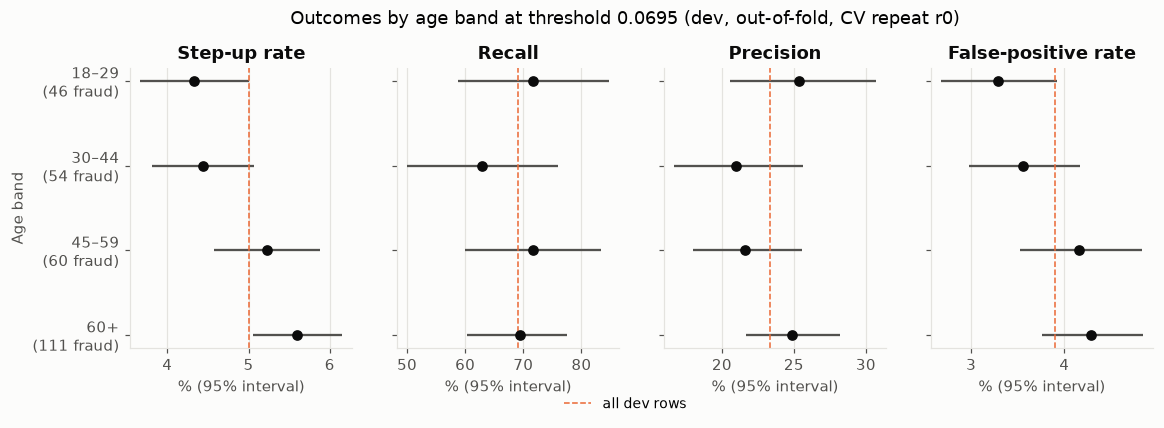

In [4]:
fig, axes = P.plt.subplots(1, 4, figsize=(12, 3.3), sharey=True)
ypos = np.arange(len(AGE_LABELS))[::-1]
for ax, k in zip(axes, METRICS, strict=True):
    v, a, b = 100 * gm[k], 100 * gm[f"{k}_ci_low"], 100 * gm[f"{k}_ci_high"]
    ax.errorbar(
        v, ypos, xerr=[v - a, b - v], fmt="o", color=P.INK, ecolor=P.INK_2, capsize=0, lw=1.5
    )
    ax.axvline(100 * overall[k], color=P.SERIES[1], ls="--", lw=1, label="all dev rows")
    ax.set_title(LABEL[k])
    ax.set_xlabel("% (95% interval)")
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(
    ypos, [f"{g}\n({n} fraud)" for g, n in zip(gm["group"], gm["n_fraud"], strict=True)]
)
axes[0].set_ylabel("Age band")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.1), frameon=False, fontsize=9
)
fig.suptitle(
    f"Outcomes by age band at threshold {thr:.4f} (dev, out-of-fold, CV repeat r0)", y=1.04
)
P.save(fig, "p5_fairness")
P.plt.show()

## 3. Is any band different from the rest? (pre-registered rule)

Difference = band − all other dev rows. The verdict uses the Bonferroni interval
(1 − 0.05/16 ≈ 99.69%); the 95% interval is shown for reference.

In [5]:
gaps = group_gaps(r0["y"], r0["score"], r0["age_group"], thr)
gtab = gaps.assign(
    metric=gaps["metric"].map(LABEL),
    diff_pp=100 * gaps["diff"],
    ci95_pp=[
        f"[{100 * a:+.1f}, {100 * b:+.1f}]"
        for a, b in zip(gaps["ci_low"], gaps["ci_high"], strict=True)
    ],
    ci_adj_pp=[
        f"[{100 * a:+.1f}, {100 * b:+.1f}]"
        for a, b in zip(gaps["ci_adj_low"], gaps["ci_adj_high"], strict=True)
    ],
)[["group", "metric", "diff_pp", "ci95_pp", "ci_adj_pp", "verdict"]]
write_csv(gaps, "p5_fairness_gaps")
gtab.round(2)

,group,metric,diff_pp,ci95_pp,ci_adj_pp,verdict
0,18–29,Step-up rate,-0.83,"[-1.6, -0.1]","[-1.9, +0.3]",not distinguishable
1,18–29,Recall,3.29,"[-11.2, +17.3]","[-19.1, +23.8]",not distinguishable
2,18–29,Precision,2.43,"[-3.0, +8.3]","[-5.4, +11.8]",not distinguishable
3,18–29,False-positive rate,-0.76,"[-1.5, -0.0]","[-1.8, +0.3]",not distinguishable
4,30–44,Step-up rate,-0.74,"[-1.5, -0.0]","[-1.8, +0.4]",not distinguishable
5,30–44,Recall,-7.54,"[-21.9, +6.3]","[-29.7, +12.8]",not distinguishable
6,30–44,Precision,-2.96,"[-7.9, +2.1]","[-10.2, +4.9]",not distinguishable
7,30–44,False-positive rate,-0.45,"[-1.1, +0.3]","[-1.5, +0.7]",not distinguishable
8,45–59,Step-up rate,0.29,"[-0.5, +1.0]","[-0.9, +1.4]",not distinguishable
9,45–59,Recall,3.42,"[-9.9, +16.3]","[-16.3, +22.0]",not distinguishable


In [6]:
real = gaps[gaps["verdict"] != "not distinguishable"]
# reported for transparency: gaps whose plain 95% interval excludes 0 (NOT the pre-registered rule)
hint = gaps[(gaps["ci_low"] > 0) | (gaps["ci_high"] < 0)]
widest = gaps.assign(width=gaps["ci_adj_high"] - gaps["ci_adj_low"]).sort_values("width").iloc[-1]
print(f"gaps called real: {len(real)} of {N_COMPARISONS}")
print(f"gaps whose unadjusted 95% interval excludes 0: {len(hint)}")
print(
    f"widest adjusted interval: {widest['group']} {widest['metric']} ({100 * widest['width']:.1f} pp)"
)

gaps called real: 0 of 16
gaps whose unadjusted 95% interval excludes 0: 4
widest adjusted interval: 18–29 recall (42.9 pp)


## 4. Stability: the same metrics on CV repeats r1 and r2 (point estimates)

In [7]:
stab = []
for r in (0, 1, 2):
    sub = oof[oof["repeat"] == r]
    t = group_metrics(sub["y"], sub["score"], sub["age_group"], thr, n_boot=1)
    stab.append(t[["group", *METRICS]].assign(repeat=f"r{r}"))
stab = pd.concat(stab)
stab_wide = stab.pivot(index="group", columns="repeat", values=METRICS).reindex(AGE_LABELS)
(100 * stab_wide).round(1)

stepup_rate           recall             precision              fpr  \
repeat          r0   r1   r2     r0    r1    r2        r0    r1    r2   r0   
group                                                                        
18–29          4.3  4.3  4.5   71.7  76.1  78.3      25.4  27.3  26.9  3.3   
30–44          4.4  4.3  4.3   63.0  61.1  63.0      21.0  20.9  21.7  3.6   
45–59          5.2  5.3  5.3   71.7  71.7  71.7      21.6  21.5  21.3  4.2   
60+            5.6  5.7  5.6   69.4  73.0  65.8      24.8  25.5  23.6  4.3   

                  
repeat   r1   r2  
group             
18–29   3.1  3.3  
30–44   3.5  3.4  
45–59   4.2  4.2  
60+     4.4  4.3

## 5. Does the model need `customer_age`?

In [8]:
no_age = run_cv(dev, {**final.spec, "drop": ["customer_age"]}, "logreg_no_age")
save_result(no_age, with_oof=False)
test = corrected_ttest(final, no_age, "pr_auc")
na_r0 = no_age.oof[no_age.oof["repeat"] == 0].merge(r0[[C.ID_COL, "age_group"]], on=C.ID_COL)
gm_na = group_metrics(na_r0["y"], na_r0["score"], na_r0["age_group"], thr)
cmp_age = pd.DataFrame(
    {
        "group": AGE_LABELS,
        "step-up % (with age)": 100 * gm["stepup_rate"],
        "step-up % (without)": 100 * gm_na["stepup_rate"],
        "FPR % (with age)": 100 * gm["fpr"],
        "FPR % (without)": 100 * gm_na["fpr"],
    }
)
print(
    f"PR-AUC without age minus with age: {test['mean_diff_b_minus_a']:+.3f} "
    f"[{test['ci_low']:+.3f}, {test['ci_high']:+.3f}] -> {test['verdict']}"
)
cmp_age.round(2)

PR-AUC without age minus with age: -0.002 [-0.008, +0.005] -> not distinguishable


,group,step-up % (with age),step-up % (without),FPR % (with age),FPR % (without)
0,18–29,4.33,5.13,3.28,4.06
1,30–44,4.44,4.68,3.56,3.81
2,45–59,5.23,5.20,4.16,4.16
3,60+,5.60,4.96,4.29,3.68


In [9]:
shap = read_json("p2_shap")["global_importance"]
age_rank = next(i for i, x in enumerate(shap, 1) if x["feature"] == "customer_age")
age_share = next(x["mean_abs_shap"] for x in shap if x["feature"] == "customer_age") / sum(
    x["mean_abs_shap"] for x in shap
)
print(
    f"customer_age: SHAP rank {age_rank} of {len(shap)}, {100 * age_share:.1f}% of total mean |SHAP|"
)

customer_age: SHAP rank 14 of 24, 2.0% of total mean |SHAP|


In [10]:
saved = write_json(
    {
        "preregistration": "notes/00_preregistration.md#A5",
        "data": "dev out-of-fold scores of the final pipeline, CV repeat r0; holdout not used",
        "threshold": thr,
        "age_bands": AGE_LABELS,
        "n_boot": N_BOOT,
        "n_comparisons": N_COMPARISONS,
        "alpha_adjusted": ALPHA_ADJ,
        "overall": overall,
        "sizes": sizes.to_dict(orient="records"),
        "groups": gm.to_dict(orient="records"),
        "gaps": gaps.to_dict(orient="records"),
        "n_gaps_real": int(len(real)),
        "n_gaps_95_excluding_0": int(len(hint)),
        "stability": stab.to_dict(orient="records"),
        "no_age": {
            "test": test,
            "pr_auc_with_age": metric_ci(final, "pr_auc"),
            "pr_auc_without_age": metric_ci(no_age, "pr_auc"),
            "groups": gm_na.to_dict(orient="records"),
        },
        "customer_age_shap": {"rank": age_rank, "of": len(shap), "share": age_share},
    },
    "p5_fairness",
)
print("saved", saved.relative_to(C.ROOT))

saved reports/p5_fairness.json


## Summary

In [11]:
def pp(x):
    return f"{100 * x:.1f}%"


def band_line(row):
    return (
        f"| {row['group']} | {row['n']:,} | {row['n_fraud']} | {pp(row['stepup_rate'])} | "
        f"{pp(row['recall'])} [{pp(row['recall_ci_low'])}, {pp(row['recall_ci_high'])}] | "
        f"{pp(row['fpr'])} [{pp(row['fpr_ci_low'])}, {pp(row['fpr_ci_high'])}] |"
    )


def gap_txt(r, lo="ci_low", hi="ci_high"):
    return (
        f"{r['group']} {LABEL[r['metric']].lower()} {100 * r['diff']:+.2f} pp "
        f"[{100 * r[lo]:+.2f}, {100 * r[hi]:+.2f}]"
    )


if len(real):
    verdict_txt = (
        f"{len(real)} of {N_COMPARISONS} gaps pass the pre-registered rule (Bonferroni interval): "
        + "; ".join(gap_txt(r, "ci_adj_low", "ci_adj_high") for _, r in real.iterrows())
        + "."
    )
else:
    verdict_txt = (
        f"None of the {N_COMPARISONS} gaps passes the pre-registered rule, so all are **not "
        "distinguishable** with this much data. That is not evidence that the model is fair."
    )
if len(hint):
    hint_txt = (
        f"Without the multiple-comparison correction, {len(hint)} gaps have a 95% interval that excludes 0: "
        + "; ".join(gap_txt(r) for _, r in hint.iterrows())
        + ". "
        + (
            "They point the same way (older bands above the rest, younger bands below), but"
            if all((r["diff"] > 0) == (r["group"] in ("45–59", "60+")) for _, r in hint.iterrows())
            else "They"
        )
        + " do not pass the pre-registered rule: a lead to re-check on more data, not a finding."
    )
else:
    hint_txt = "No gap excludes 0 even at the unadjusted 95% level."

band = sizes.set_index("age_group")
su = gm.set_index("group")
sn = gm_na.set_index("group")
age_effect_txt = (
    f"Removing age changes who is stepped up: 18–29 goes from {pp(su.loc['18–29', 'stepup_rate'])} to "
    f"{pp(sn.loc['18–29', 'stepup_rate'])}, 60+ from {pp(su.loc['60+', 'stepup_rate'])} to "
    f"{pp(sn.loc['60+', 'stepup_rate'])} (descriptive). Part of the age pattern follows the base rate: "
    f"fraud is {band.loc['60+', 'fraud_rate_%']:.2f}% of 60+ rows vs {band.loc['18–29', 'fraud_rate_%']:.2f}% "
    "of 18–29 rows on dev."
)

display(
    Markdown(f"""
**Answers** (dev, out-of-fold, threshold {thr:.4f}; 95% bootstrap intervals; holdout not used)

| Age band | Rows | Fraud | Step-up rate | Recall | False-positive rate |
|---|---|---|---|---|---|
{chr(10).join(band_line(r) for _, r in gm.iterrows())}

1. **Per band.** Fraud cases per band range from {gm["n_fraud"].min()} to {gm["n_fraud"].max()}, so recall
   intervals are wide (up to {100 * (gm["recall_ci_high"] - gm["recall_ci_low"]).max():.0f} pp).
2. **Gaps.** {verdict_txt} The widest Bonferroni interval spans {100 * widest["width"]:.1f} pp
   ({widest["group"]}, {LABEL[widest["metric"]].lower()}). {hint_txt}
3. **Without `customer_age`.** PR-AUC changes by {test["mean_diff_b_minus_a"]:+.3f}
   [{test["ci_low"]:+.3f}, {test["ci_high"]:+.3f}] (paired, 15 folds): **{test["verdict"]}**.
   Age ranks {age_rank} of {len(shap)} features by mean |SHAP| ({100 * age_share:.1f}% of the total).
   {age_effect_txt} The final model is unchanged (the holdout has been used); dropping age costs no
   distinguishable PR-AUC and is an option where using age is not acceptable.
""")
)


**Answers** (dev, out-of-fold, threshold 0.0695; 95% bootstrap intervals; holdout not used)

| Age band | Rows | Fraud | Step-up rate | Recall | False-positive rate |
|---|---|---|---|---|---|
| 18–29 | 3,000 | 46 | 4.3% | 71.7% [58.7%, 84.8%] | 3.3% [2.7%, 3.9%] |
| 30–44 | 3,652 | 54 | 4.4% | 63.0% [50.0%, 75.9%] | 3.6% [3.0%, 4.2%] |
| 45–59 | 3,808 | 60 | 5.2% | 71.7% [60.0%, 83.3%] | 4.2% [3.5%, 4.8%] |
| 60+ | 5,540 | 111 | 5.6% | 69.4% [60.4%, 77.5%] | 4.3% [3.8%, 4.8%] |

1. **Per band.** Fraud cases per band range from 46 to 111, so recall
   intervals are wide (up to 26 pp).
2. **Gaps.** None of the 16 gaps passes the pre-registered rule, so all are **not distinguishable** with this much data. That is not evidence that the model is fair. The widest Bonferroni interval spans 42.9 pp
   (18–29, recall). Without the multiple-comparison correction, 4 gaps have a 95% interval that excludes 0: 18–29 step-up rate -0.83 pp [-1.57, -0.06]; 18–29 false-positive rate -0.76 pp [-1.49, -0.02]; 30–44 step-up rate -0.74 pp [-1.46, -0.01]; 60+ step-up rate +0.90 pp [+0.22, +1.57]. They point the same way (older bands above the rest, younger bands below), but do not pass the pre-registered rule: a lead to re-check on more data, not a finding.
3. **Without `customer_age`.** PR-AUC changes by -0.002
   [-0.008, +0.005] (paired, 15 folds): **not distinguishable**.
   Age ranks 14 of 24 features by mean |SHAP| (2.0% of the total).
   Removing age changes who is stepped up: 18–29 goes from 4.3% to 5.1%, 60+ from 5.6% to 5.0% (descriptive). Part of the age pattern follows the base rate: fraud is 2.00% of 60+ rows vs 1.53% of 18–29 rows on dev. The final model is unchanged (the holdout has been used); dropping age costs no
   distinguishable PR-AUC and is an option where using age is not acceptable.
